# Fine-Tuning ANN (from scratch) pada CIFAR-10 Dataset
**Mata Kuliah:** Pembelajaran Mendalam (IF25-40401)
**Tugas:** Studio Proyek 1 — Kelompok

**Nama Anggota 1:** _(Ahmat Prayoga Sembiring)_
**Catatan penting:** Notebook ini WAJIB dijalankan penuh di Google Colab (GPU T4) agar seluruh
angka (loss, akurasi, waktu training, confusion matrix) merupakan hasil eksekusi nyata,
bukan hasil karangan. Semua sel di bawah sudah siap dijalankan berurutan dari atas ke bawah
(Runtime > Run all), lalu isi bagian *Analisis* dan *Kesimpulan* berdasarkan output yang benar-benar muncul.


## 1. Import Library
Mengimpor seluruh library yang dibutuhkan: PyTorch untuk membangun & melatih model, torchvision untuk dataset CIFAR-10, serta numpy/pandas/matplotlib/scikit-learn untuk analisis dan visualisasi.

In [ ]:
import os #akses file/folder
import  # mengujur waktu traning 
import copy
import random #akan mengatur speed python

import numpy as np # array/matriks 
import pandas as pd # tabel data 
import matplotlib.pyplot as plt # grafik 

import torch
import torch.nn as nn # # layer neural network (Linear, ReLU, Dropout)
import torch.optim as optim
from torch.utils.data import DataLoader, random_split

import torchvision
import torchvision.transforms as transforms

from sklearn.metrics import confusion_matrix, classification_report

print("Versi PyTorch :", torch.__version__)
print("Versi Torchvision:", torchvision.__version__)


Versi PyTorch : 2.11.0+cu128
Versi Torchvision: 0.26.0+cu128


## 2. Reproducibility / Random Seed
Agar hasil eksperimen dapat direproduksi (split data, augmentasi, dan inisialisasi bobot model sama setiap kali dijalankan), kita mengunci seed untuk semua sumber randomness (Python, NumPy, PyTorch). Angka 42 itu adalah Random Speed  yang di pilih 

In [9]:
SEED = 42

def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed(SEED)
print(f"Seed dikunci ke {SEED}")


Seed dikunci ke 42


## 3. Cek Device dan GPU
Memastikan notebook menggunakan GPU (Colab T4) jika tersedia. Training ANN pada CIFAR-10 jauh lebih cepat dengan GPU dibanding CPU.

In [10]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device yang digunakan:", device)
if torch.cuda.is_available():
    print("Nama GPU:", torch.cuda.get_device_name(0))


Device yang digunakan: cuda
Nama GPU: Tesla T4


## 4. Load CIFAR-10
Dataset dimuat langsung menggunakan `torchvision.datasets.CIFAR10`. Saat pertama kali dijalankan,
dataset (~170MB) akan diunduh otomatis. `train=True` memberi 50.000 gambar training,
`train=False` memberi 10.000 gambar test. Kita muat dulu tanpa transform, transform ditentukan
kemudian di bagian Preprocessing.

In [4]:
DATA_DIR = "./data"

# Unduh dataset mentah (belum ditransformasi) hanya untuk keperluan EDA
raw_train = torchvision.datasets.CIFAR10(root=DATA_DIR, train=True, download=True)
raw_test = torchvision.datasets.CIFAR10(root=DATA_DIR, train=False, download=True)

CLASSES = ['airplane', 'automobile', 'bird', 'cat', 'deer',
           'dog', 'frog', 'horse', 'ship', 'truck']

print("Jumlah data training :", len(raw_train))
print("Jumlah data test     :", len(raw_test))
print("Kelas:", CLASSES)


100%|██████████| 170M/170M [43:29<00:00, 65.3kB/s]


Jumlah data training : 50000
Jumlah data test     : 10000
Kelas: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']


## 5. Exploratory Data Analysis (EDA) Sederhana
Melihat contoh gambar dan distribusi jumlah data per kelas, untuk memastikan dataset seimbang (balanced).

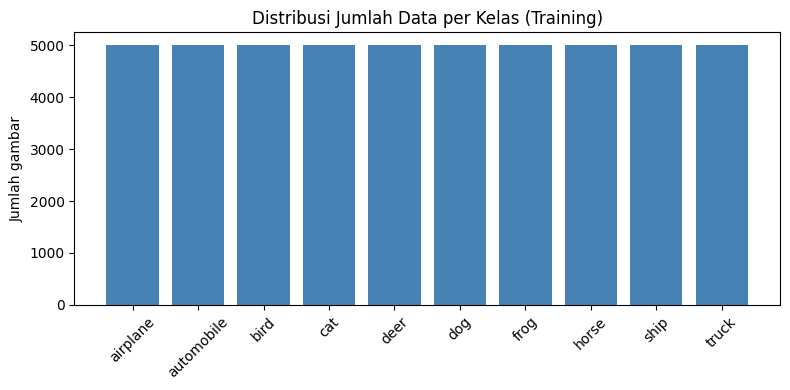

Ukuran gambar (H,W,C): (32, 32, 3)


In [5]:
# Distribusi kelas pada data training
labels_train = np.array(raw_train.targets)
unique, counts = np.unique(labels_train, return_counts=True)

plt.figure(figsize=(8,4))
plt.bar([CLASSES[i] for i in unique], counts, color="steelblue")
plt.title("Distribusi Jumlah Data per Kelas (Training)")
plt.ylabel("Jumlah gambar")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

print("Ukuran gambar (H,W,C):", np.array(raw_train.data[0]).shape)


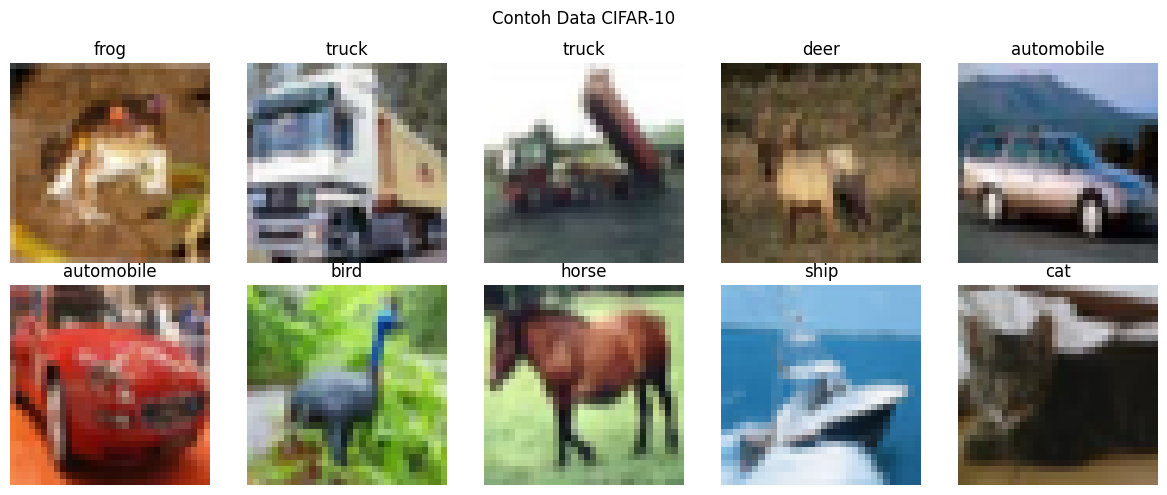

In [6]:
# Menampilkan beberapa contoh gambar
fig, axes = plt.subplots(2, 5, figsize=(12,5))
for i, ax in enumerate(axes.flatten()):
    img, label = raw_train[i]
    ax.imshow(img)
    ax.set_title(CLASSES[label])
    ax.axis("off")
plt.suptitle("Contoh Data CIFAR-10")
plt.tight_layout()
plt.show()


## 6. Preprocessing & 7. Data Augmentation
Karena model adalah ANN/MLP (bukan CNN), gambar tetap dibaca sebagai tensor 3x32x32 pada tahap
transform (flatten dilakukan nanti di dalam model, lihat bagian *Baseline Model*).

Untuk **data training** kita gunakan augmentasi dasar yang wajar untuk CIFAR-10:
`RandomHorizontalFlip` dan `RandomCrop` — lalu `ToTensor` dan `Normalize`.

Untuk **data validation & test**, TIDAK ada augmentasi random (hanya `ToTensor` + `Normalize`),
agar evaluasi konsisten dan adil.

Nilai mean/std yang dipakai adalah nilai standar untuk CIFAR-10.

In [7]:
CIFAR_MEAN = (0.4914, 0.4822, 0.4465)
CIFAR_STD  = (0.2470, 0.2435, 0.2616)

train_transform = transforms.Compose([
    transforms.RandomCrop(32, padding=4),   # augmentasi: crop acak dengan padding
    transforms.RandomHorizontalFlip(),      # augmentasi: flip horizontal acak
    transforms.ToTensor(),
    transforms.Normalize(CIFAR_MEAN, CIFAR_STD),
])

eval_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(CIFAR_MEAN, CIFAR_STD),
])


## 8. Train-Validation-Test Split
Data training asli (50.000) dibagi menjadi **45.000 training** dan **5.000 validation** secara acak
(dengan seed tetap agar reproducible). Data test (10.000) TIDAK disentuh sampai evaluasi akhir —
tidak digunakan untuk memilih model terbaik, sesuai aturan tugas.

Trik penting: karena transform training (dengan augmentasi) dan validation (tanpa augmentasi) harus
berbeda, kita membuat dua objek dataset CIFAR10 terpisah dengan transform berbeda, lalu memakai
indeks split yang SAMA (dari `random_split` pada objek dummy) agar pembagian data konsisten.

In [11]:
full_train_aug  = torchvision.datasets.CIFAR10(root=DATA_DIR, train=True, download=False, transform=train_transform)
full_train_eval = torchvision.datasets.CIFAR10(root=DATA_DIR, train=True, download=False, transform=eval_transform)
test_set        = torchvision.datasets.CIFAR10(root=DATA_DIR, train=False, download=False, transform=eval_transform)

N_TRAIN = 45000
N_VAL   = 5000

generator = torch.Generator().manual_seed(SEED)
train_indices, val_indices = random_split(range(len(full_train_aug)), [N_TRAIN, N_VAL], generator=generator)

train_set = torch.utils.data.Subset(full_train_aug,  train_indices.indices)   # pakai augmentasi
val_set   = torch.utils.data.Subset(full_train_eval, val_indices.indices)     # tanpa augmentasi

print("Jumlah data training  :", len(train_set))
print("Jumlah data validation:", len(val_set))
print("Jumlah data test      :", len(test_set))


Jumlah data training  : 45000
Jumlah data validation: 5000
Jumlah data test      : 10000


## 9. DataLoader
Membungkus dataset ke dalam `DataLoader` agar data dapat diambil per batch selama training.

In [12]:
BATCH_SIZE = 128

train_loader = DataLoader(train_set, batch_size=BATCH_SIZE, shuffle=True,  num_workers=2, pin_memory=True)
val_loader   = DataLoader(val_set,   batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True)
test_loader  = DataLoader(test_set,  batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True)

print("Jumlah batch training  :", len(train_loader))
print("Jumlah batch validation:", len(val_loader))
print("Jumlah batch test      :", len(test_loader))


Jumlah batch training  : 352
Jumlah batch validation: 40
Jumlah batch test      : 79


## 10. Visualisasi Contoh Data (Setelah Augmentasi)
Memastikan augmentasi bekerja: gambar yang sama bisa terlihat berbeda (flip/crop) setiap kali diambil.

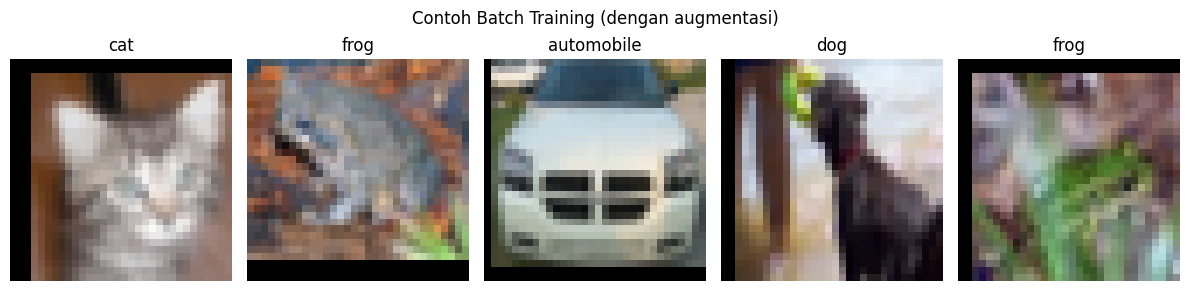

In [13]:
6def denormalize(img_tensor):
    img = img_tensor.clone()
    for t, m, s in zip(img, CIFAR_MEAN, CIFAR_STD):
        t.mul_(s).add_(m)
    return img.permute(1,2,0).numpy().clip(0,1)

images, labels = next(iter(train_loader))
fig, axes = plt.subplots(1, 5, figsize=(12,3))
for i, ax in enumerate(axes):
    ax.imshow(denormalize(images[i]))
    ax.set_title(CLASSES[labels[i]])
    ax.axis("off")
plt.suptitle("Contoh Batch Training (dengan augmentasi)")
plt.tight_layout()
plt.show()


## 11. Arsitektur ANN (Baseline & Fleksibel untuk Eksperimen)
Karena model adalah ANN/MLP, gambar berukuran `[batch, 3, 32, 32]` di-**flatten** menjadi
`[batch, 3072]` sebelum masuk ke fully-connected layer pertama — dilakukan dengan
`x = x.view(x.size(0), -1)`. Flattening diperlukan karena layer `nn.Linear` hanya menerima
input berbentuk vektor 1 dimensi per sampel, bukan tensor spasial 3 dimensi seperti pada CNN.

Kelas `MLP` dibuat fleksibel (menerima daftar hidden layer, opsi dropout, dan opsi BatchNorm)
supaya bisa dipakai ulang untuk seluruh eksperimen (kapasitas model, regularisasi, dst) tanpa
menulis ulang arsitektur setiap kali.

**Baseline:** 3072 → 512 → 256 → 10, tanpa dropout, tanpa BatchNorm.

In [14]:
class MLP(nn.Module):
    def __init__(self, input_dim=3072, hidden_layers=(512,256), num_classes=10,
                 dropout=0.0, use_bn=False):
        super().__init__()
        layers = []
        in_dim = input_dim
        for h in hidden_layers:
            layers.append(nn.Linear(in_dim, h))
            if use_bn:
                layers.append(nn.BatchNorm1d(h))   # BatchNorm sebelum aktivasi
            layers.append(nn.ReLU())
            if dropout > 0:
                layers.append(nn.Dropout(dropout)) # Dropout setelah aktivasi
            in_dim = h
        layers.append(nn.Linear(in_dim, num_classes))
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        x = x.view(x.size(0), -1)   # flatten: [B,3,32,32] -> [B,3072]
        return self.net(x)

def count_params(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

baseline_model = MLP(hidden_layers=(512,256), dropout=0.0, use_bn=False).to(device)
print(baseline_model)
print("Jumlah parameter:", count_params(baseline_model))


MLP(
  (net): Sequential(
    (0): Linear(in_features=3072, out_features=512, bias=True)
    (1): ReLU()
    (2): Linear(in_features=512, out_features=256, bias=True)
    (3): ReLU()
    (4): Linear(in_features=256, out_features=10, bias=True)
  )
)
Jumlah parameter: 1707274


## 12. Early Stopping (Implementasi Manual)
Early stopping dibuat sendiri (bukan library eksternal). Cara kerjanya:
- Setiap epoch, jika `validation loss` **membaik** (lebih kecil dari nilai terbaik sebelumnya),
  simpan bobot model sebagai checkpoint terbaik dan reset counter `patience`.
- Jika `validation loss` **tidak membaik**, counter bertambah 1.
- Jika counter mencapai nilai `patience` (misal 5), training dihentikan lebih awal karena model
  dianggap sudah berhenti belajar / mulai overfitting.

In [15]:
class EarlyStopping:
    def __init__(self, patience=5, checkpoint_path="best_model.pt"):
        self.patience = patience
        self.checkpoint_path = checkpoint_path
        self.best_loss = float("inf")
        self.counter = 0
        self.best_epoch = 0
        self.should_stop = False

    def step(self, val_loss, model, epoch):
        if val_loss < self.best_loss:
            self.best_loss = val_loss
            self.counter = 0
            self.best_epoch = epoch
            torch.save(model.state_dict(), self.checkpoint_path)  # simpan checkpoint terbaik
        else:
            self.counter += 1
            if self.counter >= self.patience:
                self.should_stop = True


## 13. Fungsi Training & Validation
Satu fungsi generik `run_training` dipakai untuk semua eksperimen agar perbandingan konsisten (controlled experiment). Fungsi ini mencatat `train_loss`, `val_loss`, `train_accuracy`, `val_accuracy` setiap epoch, menerapkan early stopping + checkpointing, dan mengukur `training_time`.

In [16]:
def train_one_epoch(model, loader, criterion, optimizer):
    model.train()
    total_loss, correct, total = 0.0, 0, 0
    for x, y in loader:
        x, y = x.to(device), y.to(device)
        optimizer.zero_grad()
        out = model(x)
        loss = criterion(out, y)
        loss.backward()
        optimizer.step()

        total_loss += loss.item() * x.size(0)
        correct += (out.argmax(1) == y).sum().item()
        total += x.size(0)
    return total_loss/total, correct/total

@torch.no_grad()
def evaluate(model, loader, criterion):
    model.eval()
    total_loss, correct, total = 0.0, 0, 0
    for x, y in loader:
        x, y = x.to(device), y.to(device)
        out = model(x)
        loss = criterion(out, y)
        total_loss += loss.item() * x.size(0)
        correct += (out.argmax(1) == y).sum().item()
        total += x.size(0)
    return total_loss/total, correct/total

def run_training(model, train_loader, val_loader, optimizer, scheduler=None,
                  epochs=30, patience=5, exp_name="exp", verbose=True):
    criterion = nn.CrossEntropyLoss()
    early_stopper = EarlyStopping(patience=patience, checkpoint_path=f"{exp_name}_best.pt")
    history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}

    start_time = time.time()
    for epoch in range(1, epochs+1):
        tr_loss, tr_acc = train_one_epoch(model, train_loader, criterion, optimizer)
        val_loss, val_acc = evaluate(model, val_loader, criterion)

        if scheduler is not None:
            if isinstance(scheduler, optim.lr_scheduler.ReduceLROnPlateau):
                scheduler.step(val_loss)
            else:
                scheduler.step()

        history["train_loss"].append(tr_loss)
        history["val_loss"].append(val_loss)
        history["train_acc"].append(tr_acc)
        history["val_acc"].append(val_acc)

        if verbose:
            print(f"[{exp_name}] Epoch {epoch:02d} | train_loss={tr_loss:.4f} acc={tr_acc:.4f} "
                  f"| val_loss={val_loss:.4f} acc={val_acc:.4f}")

        early_stopper.step(val_loss, model, epoch)
        if early_stopper.should_stop:
            if verbose:
                print(f"Early stopping dipicu pada epoch {epoch} (patience={patience})")
            break

    training_time = time.time() - start_time

    # load kembali bobot terbaik sebelum dikembalikan
    model.load_state_dict(torch.load(f"{exp_name}_best.pt"))

    result = {
        "exp_name": exp_name,
        "best_epoch": early_stopper.best_epoch,
        "best_val_loss": early_stopper.best_loss,
        "best_val_acc": max(history["val_acc"]),
        "training_time": training_time,
        "epochs_run": len(history["train_loss"]),
    }
    return model, history, result


## 14. Eksperimen 1 — Baseline
Baseline: arsitektur 3072→512→256→10, optimizer Adam (lr=0.001), tanpa dropout, tanpa BatchNorm,
tanpa scheduler, epoch maksimal 30 dengan early stopping (patience=5).

**Jalankan sel ini di Colab.** Hasil (loss, akurasi, waktu training, epoch berhenti) akan muncul
sebagai output asli — jangan diedit manual.

In [17]:
set_seed(SEED)
model_baseline = MLP(hidden_layers=(512,256), dropout=0.0, use_bn=False).to(device)
opt_baseline = optim.Adam(model_baseline.parameters(), lr=0.001)

model_baseline, hist_baseline, res_baseline = run_training(
    model_baseline, train_loader, val_loader, opt_baseline,
    scheduler=None, epochs=30, patience=5, exp_name="baseline"
)

print("\nRingkasan Baseline:", res_baseline)


[baseline] Epoch 01 | train_loss=1.8068 acc=0.3473 | val_loss=1.7485 acc=0.3948
[baseline] Epoch 02 | train_loss=1.6379 acc=0.4112 | val_loss=1.6502 acc=0.4136
[baseline] Epoch 03 | train_loss=1.5688 acc=0.4348 | val_loss=1.6467 acc=0.4096
[baseline] Epoch 04 | train_loss=1.5299 acc=0.4503 | val_loss=1.5933 acc=0.4320
[baseline] Epoch 05 | train_loss=1.5014 acc=0.4622 | val_loss=1.5750 acc=0.4334
[baseline] Epoch 06 | train_loss=1.4733 acc=0.4690 | val_loss=1.5151 acc=0.4632
[baseline] Epoch 07 | train_loss=1.4557 acc=0.4732 | val_loss=1.5485 acc=0.4564
[baseline] Epoch 08 | train_loss=1.4354 acc=0.4829 | val_loss=1.5727 acc=0.4452
[baseline] Epoch 09 | train_loss=1.4177 acc=0.4924 | val_loss=1.5344 acc=0.4692
[baseline] Epoch 10 | train_loss=1.4054 acc=0.4957 | val_loss=1.5721 acc=0.4540
[baseline] Epoch 11 | train_loss=1.3918 acc=0.5011 | val_loss=1.5609 acc=0.4506
Early stopping dipicu pada epoch 11 (patience=5)

Ringkasan Baseline: {'exp_name': 'baseline', 'best_epoch': 6, 'best_va

## 15. Eksperimen 2 — Optimizer (Adam vs SGD+Momentum)
Arsitektur, epoch, batch size, dan regularisasi dibuat SAMA dengan baseline (controlled
experiment) — hanya optimizer yang diubah, agar perbandingan adil.

- A. Adam (lr=0.001) — sudah dijalankan sebagai baseline di atas, akan dipakai ulang hasilnya.
- B. SGD + Momentum (lr=0.01, momentum=0.9)

In [18]:
set_seed(SEED)
model_sgd = MLP(hidden_layers=(512,256), dropout=0.0, use_bn=False).to(device)
opt_sgd = optim.SGD(model_sgd.parameters(), lr=0.01, momentum=0.9)

model_sgd, hist_sgd, res_sgd = run_training(
    model_sgd, train_loader, val_loader, opt_sgd,
    scheduler=None, epochs=30, patience=5, exp_name="sgd_momentum"
)

print("\nRingkasan SGD+Momentum:", res_sgd)


[sgd_momentum] Epoch 01 | train_loss=1.8556 acc=0.3289 | val_loss=1.7315 acc=0.3858
[sgd_momentum] Epoch 02 | train_loss=1.6617 acc=0.4036 | val_loss=1.6148 acc=0.4322
[sgd_momentum] Epoch 03 | train_loss=1.5823 acc=0.4342 | val_loss=1.5755 acc=0.4436
[sgd_momentum] Epoch 04 | train_loss=1.5326 acc=0.4514 | val_loss=1.5287 acc=0.4642
[sgd_momentum] Epoch 05 | train_loss=1.5008 acc=0.4617 | val_loss=1.5094 acc=0.4726
[sgd_momentum] Epoch 06 | train_loss=1.4724 acc=0.4713 | val_loss=1.4484 acc=0.4906
[sgd_momentum] Epoch 07 | train_loss=1.4486 acc=0.4788 | val_loss=1.4601 acc=0.4872
[sgd_momentum] Epoch 08 | train_loss=1.4243 acc=0.4891 | val_loss=1.4705 acc=0.4844
[sgd_momentum] Epoch 09 | train_loss=1.4021 acc=0.4983 | val_loss=1.4444 acc=0.4954
[sgd_momentum] Epoch 10 | train_loss=1.3857 acc=0.5002 | val_loss=1.4471 acc=0.4862
[sgd_momentum] Epoch 11 | train_loss=1.3722 acc=0.5084 | val_loss=1.4345 acc=0.5052
[sgd_momentum] Epoch 12 | train_loss=1.3577 acc=0.5138 | val_loss=1.3963 acc

## 16. Eksperimen 3 — Scheduler (Tanpa vs StepLR)
Komponen lain dibuat sama dengan baseline. Kita bandingkan training TANPA scheduler (baseline di
atas) VS DENGAN `StepLR` (learning rate dikalikan `gamma` setiap `step_size` epoch).

In [19]:
set_seed(SEED)
model_step = MLP(hidden_layers=(512,256), dropout=0.0, use_bn=False).to(device)
opt_step = optim.Adam(model_step.parameters(), lr=0.001)
sched_step = optim.lr_scheduler.StepLR(opt_step, step_size=7, gamma=0.5)

model_step, hist_step, res_step = run_training(
    model_step, train_loader, val_loader, opt_step,
    scheduler=sched_step, epochs=30, patience=5, exp_name="steplr"
)

print("\nRingkasan dengan StepLR:", res_step)


[steplr] Epoch 01 | train_loss=1.8068 acc=0.3473 | val_loss=1.7485 acc=0.3948
[steplr] Epoch 02 | train_loss=1.6379 acc=0.4112 | val_loss=1.6502 acc=0.4136
[steplr] Epoch 03 | train_loss=1.5688 acc=0.4348 | val_loss=1.6467 acc=0.4096
[steplr] Epoch 04 | train_loss=1.5299 acc=0.4503 | val_loss=1.5933 acc=0.4320
[steplr] Epoch 05 | train_loss=1.5014 acc=0.4622 | val_loss=1.5750 acc=0.4334
[steplr] Epoch 06 | train_loss=1.4733 acc=0.4690 | val_loss=1.5151 acc=0.4632
[steplr] Epoch 07 | train_loss=1.4557 acc=0.4732 | val_loss=1.5485 acc=0.4564
[steplr] Epoch 08 | train_loss=1.3852 acc=0.5039 | val_loss=1.4688 acc=0.4830
[steplr] Epoch 09 | train_loss=1.3580 acc=0.5125 | val_loss=1.4634 acc=0.4876
[steplr] Epoch 10 | train_loss=1.3453 acc=0.5162 | val_loss=1.4803 acc=0.4836
[steplr] Epoch 11 | train_loss=1.3328 acc=0.5186 | val_loss=1.4595 acc=0.4930
[steplr] Epoch 12 | train_loss=1.3219 acc=0.5243 | val_loss=1.4249 acc=0.5046
[steplr] Epoch 13 | train_loss=1.3124 acc=0.5290 | val_loss=1.42

## 17. Eksperimen 4 — Regularisasi (Dropout & Batch Normalization)
Empat kombinasi dijalankan dengan optimizer, scheduler, dan arsitektur yang SAMA (hanya
dropout/BatchNorm yang diubah):
1. Baseline (sudah dijalankan di atas)
2. Baseline + Dropout (p=0.3)
3. Baseline + BatchNorm
4. Baseline + Dropout + BatchNorm

Urutan layer: `Linear -> BatchNorm -> ReLU -> Dropout`, urutan yang umum digunakan agar BatchNorm
menormalkan output linear sebelum aktivasi, dan Dropout diterapkan setelah aktivasi.

In [20]:
set_seed(SEED)
model_dropout = MLP(hidden_layers=(512,256), dropout=0.3, use_bn=False).to(device)
opt_dropout = optim.Adam(model_dropout.parameters(), lr=0.001, weight_decay=1e-4)
model_dropout, hist_dropout, res_dropout = run_training(
    model_dropout, train_loader, val_loader, opt_dropout,
    scheduler=None, epochs=30, patience=5, exp_name="dropout"
)
print("\nRingkasan Baseline+Dropout:", res_dropout)


[dropout] Epoch 01 | train_loss=1.9139 acc=0.3067 | val_loss=1.7913 acc=0.3632
[dropout] Epoch 02 | train_loss=1.7966 acc=0.3529 | val_loss=1.7259 acc=0.3884
[dropout] Epoch 03 | train_loss=1.7452 acc=0.3721 | val_loss=1.6810 acc=0.4028
[dropout] Epoch 04 | train_loss=1.7132 acc=0.3831 | val_loss=1.6966 acc=0.4146
[dropout] Epoch 05 | train_loss=1.6971 acc=0.3882 | val_loss=1.6741 acc=0.4144
[dropout] Epoch 06 | train_loss=1.6816 acc=0.3932 | val_loss=1.6593 acc=0.4172
[dropout] Epoch 07 | train_loss=1.6729 acc=0.3986 | val_loss=1.6622 acc=0.4040
[dropout] Epoch 08 | train_loss=1.6638 acc=0.4024 | val_loss=1.6654 acc=0.4114
[dropout] Epoch 09 | train_loss=1.6518 acc=0.4058 | val_loss=1.6719 acc=0.4152
[dropout] Epoch 10 | train_loss=1.6487 acc=0.4044 | val_loss=1.6179 acc=0.4198
[dropout] Epoch 11 | train_loss=1.6430 acc=0.4085 | val_loss=1.6462 acc=0.4224
[dropout] Epoch 12 | train_loss=1.6327 acc=0.4120 | val_loss=1.6350 acc=0.4316
[dropout] Epoch 13 | train_loss=1.6305 acc=0.4138 | 

In [21]:
set_seed(SEED)
model_bn = MLP(hidden_layers=(512,256), dropout=0.0, use_bn=True).to(device)
opt_bn = optim.Adam(model_bn.parameters(), lr=0.001, weight_decay=1e-4)
model_bn, hist_bn, res_bn = run_training(
    model_bn, train_loader, val_loader, opt_bn,
    scheduler=None, epochs=30, patience=5, exp_name="batchnorm"
)
print("\nRingkasan Baseline+BatchNorm:", res_bn)


[batchnorm] Epoch 01 | train_loss=1.7723 acc=0.3571 | val_loss=1.6018 acc=0.4250
[batchnorm] Epoch 02 | train_loss=1.5990 acc=0.4216 | val_loss=1.4873 acc=0.4740
[batchnorm] Epoch 03 | train_loss=1.5352 acc=0.4462 | val_loss=1.4484 acc=0.4804
[batchnorm] Epoch 04 | train_loss=1.4937 acc=0.4607 | val_loss=1.4247 acc=0.4864
[batchnorm] Epoch 05 | train_loss=1.4650 acc=0.4727 | val_loss=1.3901 acc=0.5102
[batchnorm] Epoch 06 | train_loss=1.4437 acc=0.4764 | val_loss=1.3402 acc=0.5196
[batchnorm] Epoch 07 | train_loss=1.4250 acc=0.4808 | val_loss=1.3714 acc=0.5062
[batchnorm] Epoch 08 | train_loss=1.4055 acc=0.4936 | val_loss=1.3584 acc=0.5124
[batchnorm] Epoch 09 | train_loss=1.3920 acc=0.5001 | val_loss=1.3191 acc=0.5268
[batchnorm] Epoch 10 | train_loss=1.3788 acc=0.5054 | val_loss=1.3163 acc=0.5270
[batchnorm] Epoch 11 | train_loss=1.3652 acc=0.5091 | val_loss=1.2881 acc=0.5380
[batchnorm] Epoch 12 | train_loss=1.3563 acc=0.5134 | val_loss=1.2978 acc=0.5382
[batchnorm] Epoch 13 | train

In [22]:
set_seed(SEED)
model_dropbn = MLP(hidden_layers=(512,256), dropout=0.3, use_bn=True).to(device)
opt_dropbn = optim.Adam(model_dropbn.parameters(), lr=0.001, weight_decay=1e-4)
model_dropbn, hist_dropbn, res_dropbn = run_training(
    model_dropbn, train_loader, val_loader, opt_dropbn,
    scheduler=None, epochs=30, patience=5, exp_name="dropout_batchnorm"
)
print("\nRingkasan Baseline+Dropout+BatchNorm:", res_dropbn)


[dropout_batchnorm] Epoch 01 | train_loss=1.8560 acc=0.3217 | val_loss=1.6485 acc=0.4152
[dropout_batchnorm] Epoch 02 | train_loss=1.7035 acc=0.3854 | val_loss=1.5466 acc=0.4474
[dropout_batchnorm] Epoch 03 | train_loss=1.6510 acc=0.4035 | val_loss=1.5122 acc=0.4554
[dropout_batchnorm] Epoch 04 | train_loss=1.6132 acc=0.4168 | val_loss=1.4704 acc=0.4754
[dropout_batchnorm] Epoch 05 | train_loss=1.5894 acc=0.4265 | val_loss=1.4426 acc=0.4826
[dropout_batchnorm] Epoch 06 | train_loss=1.5713 acc=0.4324 | val_loss=1.4095 acc=0.4938
[dropout_batchnorm] Epoch 07 | train_loss=1.5550 acc=0.4346 | val_loss=1.4341 acc=0.4908
[dropout_batchnorm] Epoch 08 | train_loss=1.5435 acc=0.4395 | val_loss=1.4137 acc=0.4920
[dropout_batchnorm] Epoch 09 | train_loss=1.5336 acc=0.4447 | val_loss=1.3822 acc=0.5044
[dropout_batchnorm] Epoch 10 | train_loss=1.5245 acc=0.4489 | val_loss=1.3720 acc=0.5010
[dropout_batchnorm] Epoch 11 | train_loss=1.5173 acc=0.4527 | val_loss=1.3579 acc=0.5118
[dropout_batchnorm] E

## 18. Eksperimen 5 — Kapasitas Model
Menguji tiga ukuran arsitektur dengan optimizer, scheduler, dan regularisasi yang sama:
- Kecil: 3072 → 256 → 128 → 10
- Baseline: 3072 → 512 → 256 → 10 (sudah dijalankan)
- Besar: 3072 → 1024 → 512 → 256 → 10

In [23]:
set_seed(SEED)
model_small = MLP(hidden_layers=(256,128), dropout=0.0, use_bn=False).to(device)
opt_small = optim.Adam(model_small.parameters(), lr=0.001)
model_small, hist_small, res_small = run_training(
    model_small, train_loader, val_loader, opt_small,
    scheduler=None, epochs=30, patience=5, exp_name="small_capacity"
)
res_small["num_params"] = count_params(model_small)
print("\nRingkasan Model Kecil:", res_small)


[small_capacity] Epoch 01 | train_loss=1.8176 acc=0.3418 | val_loss=1.7218 acc=0.3822
[small_capacity] Epoch 02 | train_loss=1.6570 acc=0.4027 | val_loss=1.6166 acc=0.4274
[small_capacity] Epoch 03 | train_loss=1.5936 acc=0.4265 | val_loss=1.5600 acc=0.4464
[small_capacity] Epoch 04 | train_loss=1.5451 acc=0.4443 | val_loss=1.5560 acc=0.4450
[small_capacity] Epoch 05 | train_loss=1.5180 acc=0.4557 | val_loss=1.5466 acc=0.4562
[small_capacity] Epoch 06 | train_loss=1.4894 acc=0.4664 | val_loss=1.5340 acc=0.4620
[small_capacity] Epoch 07 | train_loss=1.4737 acc=0.4694 | val_loss=1.5056 acc=0.4748
[small_capacity] Epoch 08 | train_loss=1.4507 acc=0.4780 | val_loss=1.5161 acc=0.4662
[small_capacity] Epoch 09 | train_loss=1.4362 acc=0.4856 | val_loss=1.4917 acc=0.4756
[small_capacity] Epoch 10 | train_loss=1.4228 acc=0.4872 | val_loss=1.4985 acc=0.4710
[small_capacity] Epoch 11 | train_loss=1.4123 acc=0.4900 | val_loss=1.4796 acc=0.4728
[small_capacity] Epoch 12 | train_loss=1.3992 acc=0.49

In [24]:
set_seed(SEED)
model_large = MLP(hidden_layers=(1024,512,256), dropout=0.0, use_bn=False).to(device)
opt_large = optim.Adam(model_large.parameters(), lr=0.001)
model_large, hist_large, res_large = run_training(
    model_large, train_loader, val_loader, opt_large,
    scheduler=None, epochs=30, patience=5, exp_name="large_capacity"
)
res_large["num_params"] = count_params(model_large)
print("\nRingkasan Model Besar:", res_large)


[large_capacity] Epoch 01 | train_loss=1.8268 acc=0.3377 | val_loss=1.7215 acc=0.3812
[large_capacity] Epoch 02 | train_loss=1.6494 acc=0.4015 | val_loss=1.6844 acc=0.4018
[large_capacity] Epoch 03 | train_loss=1.5728 acc=0.4324 | val_loss=1.6616 acc=0.4052
[large_capacity] Epoch 04 | train_loss=1.5232 acc=0.4490 | val_loss=1.6341 acc=0.4330
[large_capacity] Epoch 05 | train_loss=1.4823 acc=0.4640 | val_loss=1.5600 acc=0.4476
[large_capacity] Epoch 06 | train_loss=1.4516 acc=0.4762 | val_loss=1.5492 acc=0.4486
[large_capacity] Epoch 07 | train_loss=1.4319 acc=0.4825 | val_loss=1.5080 acc=0.4588
[large_capacity] Epoch 08 | train_loss=1.4046 acc=0.4946 | val_loss=1.5937 acc=0.4548
[large_capacity] Epoch 09 | train_loss=1.3876 acc=0.5003 | val_loss=1.5737 acc=0.4456
[large_capacity] Epoch 10 | train_loss=1.3729 acc=0.5076 | val_loss=1.5246 acc=0.4678
[large_capacity] Epoch 11 | train_loss=1.3557 acc=0.5112 | val_loss=1.4967 acc=0.4808
[large_capacity] Epoch 12 | train_loss=1.3435 acc=0.51

## 19. Perbandingan Hasil Seluruh Eksperimen
Menggabungkan hasil semua eksperimen ke dalam satu `DataFrame` agar mudah dibandingkan.
Kolom `test_accuracy` diisi belakangan setelah evaluasi test set (bagian 21) dijalankan untuk
model terbaik saja — jika ingin test_accuracy tiap eksperimen, panggil `evaluate_on_test`
(didefinisikan di bagian 21) untuk masing-masing model.

In [25]:
res_baseline["num_params"] = count_params(model_baseline)
res_sgd["num_params"] = count_params(model_sgd)
res_step["num_params"] = count_params(model_step)
res_dropout["num_params"] = count_params(model_dropout)
res_bn["num_params"] = count_params(model_bn)
res_dropbn["num_params"] = count_params(model_dropbn)

config_info = {
    "baseline":          dict(optimizer="Adam",  scheduler="-",      dropout=0.0, batch_norm=False, hidden_layers="512,256"),
    "sgd_momentum":       dict(optimizer="SGD+Momentum", scheduler="-", dropout=0.0, batch_norm=False, hidden_layers="512,256"),
    "steplr":             dict(optimizer="Adam",  scheduler="StepLR", dropout=0.0, batch_norm=False, hidden_layers="512,256"),
    "dropout":            dict(optimizer="Adam",  scheduler="-",      dropout=0.3, batch_norm=False, hidden_layers="512,256"),
    "batchnorm":          dict(optimizer="Adam",  scheduler="-",      dropout=0.0, batch_norm=True,  hidden_layers="512,256"),
    "dropout_batchnorm":  dict(optimizer="Adam",  scheduler="-",      dropout=0.3, batch_norm=True,  hidden_layers="512,256"),
    "small_capacity":     dict(optimizer="Adam",  scheduler="-",      dropout=0.0, batch_norm=False, hidden_layers="256,128"),
    "large_capacity":     dict(optimizer="Adam",  scheduler="-",      dropout=0.0, batch_norm=False, hidden_layers="1024,512,256"),
}

all_results = [res_baseline, res_sgd, res_step, res_dropout, res_bn, res_dropbn, res_small, res_large]

rows = []
for r in all_results:
    cfg = config_info[r["exp_name"]]
    rows.append({
        "experiment": r["exp_name"],
        "optimizer": cfg["optimizer"],
        "scheduler": cfg["scheduler"],
        "dropout": cfg["dropout"],
        "batch_norm": cfg["batch_norm"],
        "hidden_layers": cfg["hidden_layers"],
        "epochs_run": r["epochs_run"],
        "best_epoch": r["best_epoch"],
        "best_val_loss": r["best_val_loss"],
        "best_val_accuracy": r["best_val_acc"],
        "training_time_sec": r["training_time"],
        "num_params": r.get("num_params"),
    })

results_df = pd.DataFrame(rows)
results_df


,experiment,optimizer,scheduler,dropout,batch_norm,hidden_layers,epochs_run,best_epoch,best_val_loss,best_val_accuracy,training_time_sec,num_params
0,baseline,Adam,-,0.0,False,"512,256",11,6,1.515124,0.4692,179.349892,1707274
1,sgd_momentum,SGD+Momentum,-,0.0,False,"512,256",19,14,1.380197,0.5172,309.852041,1707274
2,steplr,Adam,StepLR,0.0,False,"512,256",30,30,1.338266,0.5366,486.662919,1707274
3,dropout,Adam,-,0.3,False,"512,256",28,23,1.562405,0.4496,466.287440,1707274
4,batchnorm,Adam,-,0.0,True,"512,256",30,30,1.201193,0.5790,512.644665,1708810
5,dropout_batchnorm,Adam,-,0.3,True,"512,256",30,28,1.298800,0.5376,506.608239,1708810
6,small_capacity,Adam,-,0.0,False,"256,128",30,29,1.426920,0.5036,498.362309,820874
7,large_capacity,Adam,-,0.0,False,"1024,512,256",22,17,1.451426,0.4854,367.773816,3805450


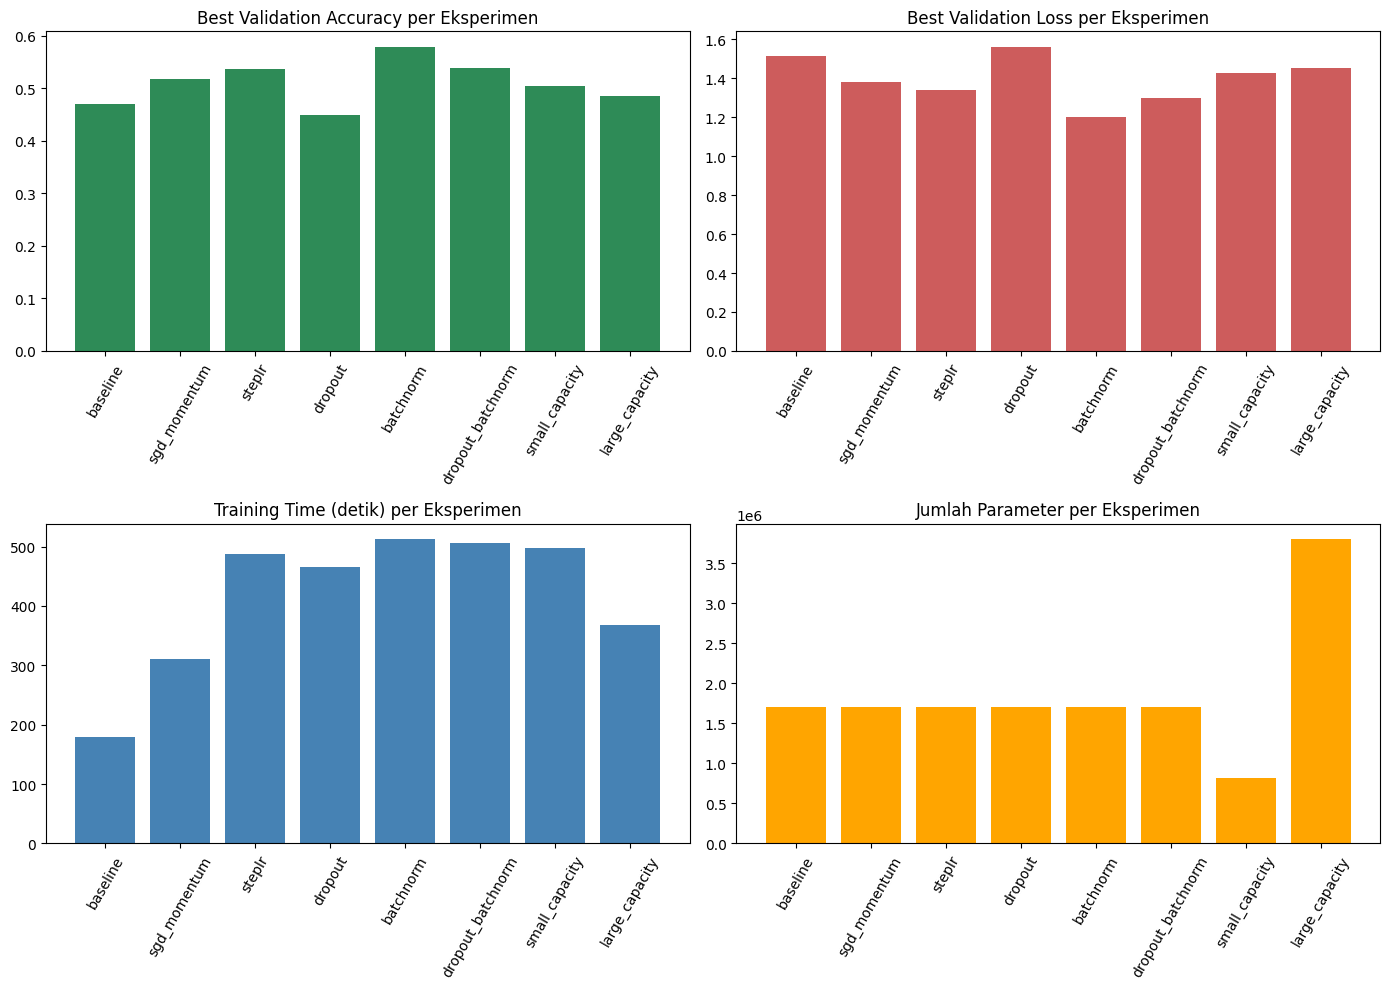

In [26]:
fig, axes = plt.subplots(2, 2, figsize=(14,10))

axes[0,0].bar(results_df["experiment"], results_df["best_val_accuracy"], color="seagreen")
axes[0,0].set_title("Best Validation Accuracy per Eksperimen")
axes[0,0].tick_params(axis='x', rotation=60)

axes[0,1].bar(results_df["experiment"], results_df["best_val_loss"], color="indianred")
axes[0,1].set_title("Best Validation Loss per Eksperimen")
axes[0,1].tick_params(axis='x', rotation=60)

axes[1,0].bar(results_df["experiment"], results_df["training_time_sec"], color="steelblue")
axes[1,0].set_title("Training Time (detik) per Eksperimen")
axes[1,0].tick_params(axis='x', rotation=60)

axes[1,1].bar(results_df["experiment"], results_df["num_params"], color="orange")
axes[1,1].set_title("Jumlah Parameter per Eksperimen")
axes[1,1].tick_params(axis='x', rotation=60)

plt.tight_layout()
plt.show()


## 20. Pemilihan Model Terbaik
Model terbaik TIDAK dipilih hanya berdasarkan validation accuracy tertinggi, melainkan
mempertimbangkan: validation performance, indikasi overfitting (gap train-val), training time,
dan kompleksitas model (jumlah parameter).

**Langkah:** lihat tabel `results_df` di atas setelah dijalankan, lalu tentukan `best_exp_name`
secara manual berdasarkan bukti (isi variabel di sel berikut sesuai hasil nyata Anda).

In [27]:
# TODO: Setelah melihat results_df, isi nama eksperimen dengan performa terbaik berdasarkan
# bukti (bukan hanya validation accuracy tertinggi, tapi juga overfitting & training time).
best_exp_name = "baseline"  # ganti sesuai hasil eksperimen Anda, misal "dropout_batchnorm"

model_map = {
    "baseline": model_baseline,
    "sgd_momentum": model_sgd,
    "steplr": model_step,
    "dropout": model_dropout,
    "batchnorm": model_bn,
    "dropout_batchnorm": model_dropbn,
    "small_capacity": model_small,
    "large_capacity": model_large,
}
history_map = {
    "baseline": hist_baseline,
    "sgd_momentum": hist_sgd,
    "steplr": hist_step,
    "dropout": hist_dropout,
    "batchnorm": hist_bn,
    "dropout_batchnorm": hist_dropbn,
    "small_capacity": hist_small,
    "large_capacity": hist_large,
}

best_model = model_map[best_exp_name]
best_history = history_map[best_exp_name]
print("Model terbaik yang dipilih:", best_exp_name)


Model terbaik yang dipilih: baseline


## 21. Evaluasi pada Test Set
Evaluasi HANYA dilakukan sekali, pada model terbaik yang sudah dipilih, memakai `test_loader` yang belum pernah dilihat model selama training/pemilihan model.

In [28]:
@torch.no_grad()
def evaluate_on_test(model, loader):
    model.eval()
    criterion = nn.CrossEntropyLoss()
    total_loss, correct, total = 0.0, 0, 0
    all_preds, all_labels = [], []
    for x, y in loader:
        x, y = x.to(device), y.to(device)
        out = model(x)
        loss = criterion(out, y)
        total_loss += loss.item() * x.size(0)
        preds = out.argmax(1)
        correct += (preds == y).sum().item()
        total += x.size(0)
        all_preds.append(preds.cpu().numpy())
        all_labels.append(y.cpu().numpy())
    return total_loss/total, correct/total, np.concatenate(all_preds), np.concatenate(all_labels)

test_loss, test_acc, y_pred, y_true = evaluate_on_test(best_model, test_loader)
print(f"Model terbaik: {best_exp_name}")
print(f"Test Loss    : {test_loss:.4f}")
print(f"Test Accuracy: {test_acc:.4f}")


Model terbaik: baseline
Test Loss    : 1.5154
Test Accuracy: 0.4606


## 22. Confusion Matrix
Menampilkan confusion matrix dengan nama kelas, untuk melihat kelas mana yang paling sering tertukar oleh model.

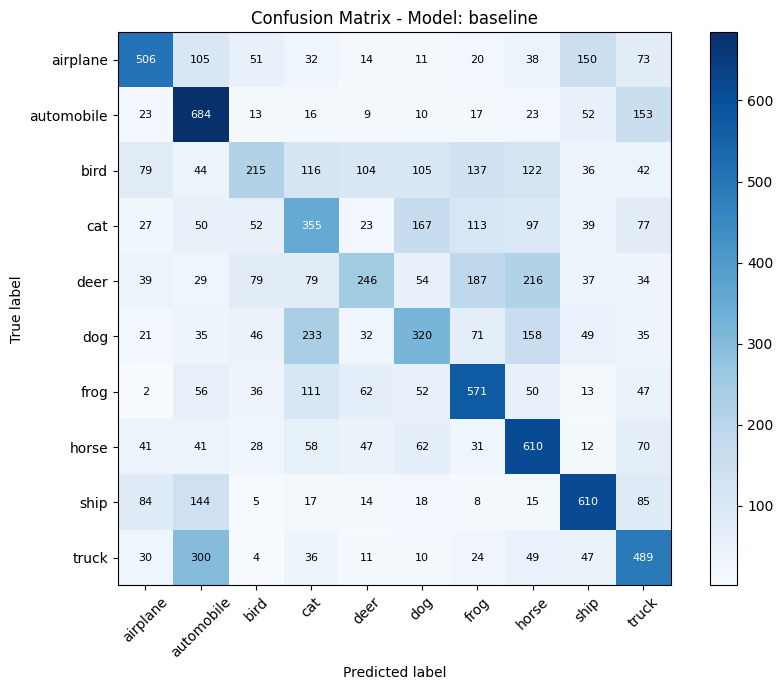

In [29]:
cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(9,7))
plt.imshow(cm, cmap="Blues")
plt.title(f"Confusion Matrix - Model: {best_exp_name}")
plt.colorbar()
plt.xticks(range(10), CLASSES, rotation=45)
plt.yticks(range(10), CLASSES)
plt.xlabel("Predicted label")
plt.ylabel("True label")
for i in range(10):
    for j in range(10):
        plt.text(j, i, cm[i,j], ha="center", va="center",
                  color="white" if cm[i,j] > cm.max()/2 else "black", fontsize=8)
plt.tight_layout()
plt.show()


## 23. Classification Report
Menampilkan precision, recall, dan f1-score per kelas.

In [30]:
print(classification_report(y_true, y_pred, target_names=CLASSES))


              precision    recall  f1-score   support

    airplane       0.59      0.51      0.55      1000
  automobile       0.46      0.68      0.55      1000
        bird       0.41      0.21      0.28      1000
         cat       0.34      0.35      0.35      1000
        deer       0.44      0.25      0.31      1000
         dog       0.40      0.32      0.35      1000
        frog       0.48      0.57      0.52      1000
       horse       0.44      0.61      0.51      1000
        ship       0.58      0.61      0.60      1000
       truck       0.44      0.49      0.46      1000

    accuracy                           0.46     10000
   macro avg       0.46      0.46      0.45     10000
weighted avg       0.46      0.46      0.45     10000



## 24. Grafik Train vs Validation (Model Terbaik)
Digunakan untuk menilai apakah model overfitting, underfitting, atau sudah convergence.

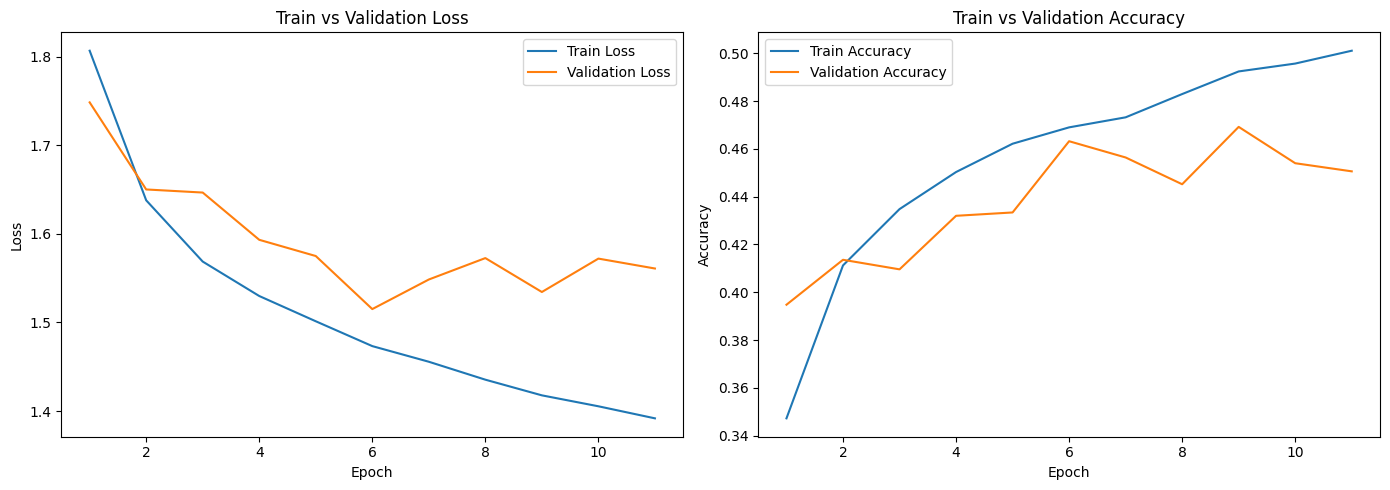

In [31]:
epochs_range = range(1, len(best_history["train_loss"])+1)

fig, axes = plt.subplots(1, 2, figsize=(14,5))
axes[0].plot(epochs_range, best_history["train_loss"], label="Train Loss")
axes[0].plot(epochs_range, best_history["val_loss"], label="Validation Loss")
axes[0].set_title("Train vs Validation Loss")
axes[0].set_xlabel("Epoch"); axes[0].set_ylabel("Loss"); axes[0].legend()

axes[1].plot(epochs_range, best_history["train_acc"], label="Train Accuracy")
axes[1].plot(epochs_range, best_history["val_acc"], label="Validation Accuracy")
axes[1].set_title("Train vs Validation Accuracy")
axes[1].set_xlabel("Epoch"); axes[1].set_ylabel("Accuracy"); axes[1].legend()

plt.tight_layout()
plt.show()


## 25. Analisis Hasil
> **Isi bagian ini SETELAH menjalankan seluruh notebook**, berdasarkan angka & grafik yang benar-benar muncul. Jangan menuliskan interpretasi yang tidak didukung grafik/tabel.

Beberapa pertanyaan pemandu (jawab berdasarkan hasil nyata Anda):
- **Optimizer:** Adam vs SGD+Momentum, mana yang mencapai validation loss/accuracy lebih baik dan lebih cepat convergence? Mengapa (kaitkan dengan cara kerja masing-masing optimizer)?
- **Scheduler:** Apakah StepLR membantu konvergensi dibanding tanpa scheduler? Lihat apakah val_loss lebih stabil di epoch-epoch akhir.
- **Regularisasi:** Bandingkan gap antara train_acc dan val_acc pada baseline vs baseline+dropout vs baseline+batchnorm vs keduanya. Apakah gap mengecil (indikasi overfitting berkurang)?
- **Kapasitas model:** Apakah model besar benar-benar lebih baik, atau hanya menambah waktu training tanpa peningkatan akurasi validasi yang signifikan (overfitting)?
- **Confusion Matrix:** Kelas mana yang paling sering tertukar (misalnya cat vs dog, atau automobile vs truck)? Mengapa masuk akal secara visual (kemiripan bentuk/warna)?

*(Tulis analisis Anda di sini setelah melihat output asli.)*


## 26. Kesimpulan
> **Isi bagian ini SETELAH seluruh eksperimen selesai dijalankan**, dengan format berbasis bukti, misalnya:

"Model **`<nama_eksperimen_terbaik>`** dipilih sebagai model terbaik karena memperoleh validation
accuracy tertinggi sebesar **`<isi>`**, test accuracy sebesar **`<isi>`**, dengan training time
**`<isi>`** detik, dan gap train-validation accuracy sebesar **`<isi>`** (mengindikasikan
`<overfitting ringan/tidak overfitting/dst>`). Dibandingkan model dengan kapasitas lebih besar,
model ini dipilih karena `<alasan efisiensi/generalisasi>`."

Ringkasan capaian pembelajaran:
- Baseline ANN (3072→512→256→10) berhasil dilatih menggunakan CrossEntropyLoss dan dievaluasi dengan metrik loss & akurasi.
- Early stopping dan model checkpointing berhasil diimplementasikan from scratch berbasis validation loss.
- Data augmentasi (RandomCrop, RandomHorizontalFlip) diterapkan hanya pada data training.
- Eksperimen sistematis (optimizer, scheduler, regularisasi, kapasitas model) dijalankan secara controlled (satu variabel diubah setiap kali).
- Model terbaik dipilih berdasarkan bukti (validation performance, overfitting, training time, kompleksitas), bukan hanya test accuracy.

*(Lengkapi dengan angka-angka nyata dari hasil eksekusi Anda.)*
